# P2.1 · MLP binary classifier on two moons

**ID:** P2.1 · **Target:** 25 min · **Plan week:** 1 (and timed repeats) · **Part:** P (PyTorch first principles)

**The drill.** From a blank notebook, build the full P0 skeleton for a 2-D binary
classification problem: data → split → normalize → `DataLoader` → `nn.Module` →
`BCEWithLogitsLoss` + AdamW → train/eval loops → sanity checks → decision-boundary plot.
Talk out loud as if an interviewer were watching.

**Must include (from the plan):** `BCEWithLogitsLoss`, accuracy, decision-boundary plot.
Also: initial-loss check (≈ ln 2 ≈ 0.693), overfit-one-batch check, `model.eval()` + `torch.no_grad()` for eval.

**Rules.** No docs, no autocomplete-from-LLM. Each cell below has its spec as comments; delete
`# YOUR CODE HERE` and write it. The **self-check** cell at the end defines the variable names
it expects; it is the only "grader". Then answer the questions out loud and log the session.

## Sources
- PyTorch tutorial, *Learn the Basics* (Datasets & DataLoaders, Build the Neural Network,
  Optimizing Model Parameters): https://docs.pytorch.org/tutorials/beginner/basics/intro.html
  (BSD-3; the skeleton order follows its train/test loop structure).
- A. Karpathy, *A Recipe for Training Neural Networks* (2019), §2 "verify loss @ init",
  "overfit one batch", "add significant digits to your eval": https://karpathy.github.io/2019/04/25/recipe/
- `torch.nn.BCEWithLogitsLoss` docs (log-sum-exp stable form, `pos_weight`):
  https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html
- scikit-learn `make_moons` and `train_test_split(stratify=...)`:
  https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html
- Decision-boundary plotting via a mesh grid, as in the scikit-learn classifier comparison example:
  https://scikit-learn.org/stable/auto_examples/classification/plot_classifier_comparison.html

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from prep import Session, check, seed_everything

s = Session("P2.1", target_min=25)
seed_everything(0)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

[P2.1] started 16:41; target 25 min


In [2]:
# 1. DATA. sklearn.datasets.make_moons(n_samples=2000, noise=0.25, random_state=0).
#    Inspect shapes, dtypes, class balance. Stratified split 70/15/15 -> X_train, X_val, X_test (+ y_*).
#    Standardize with TRAIN mean/std only (store them as `mu`, `sd`). Convert to float32 tensors.
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=2000, noise=0.25, random_state=0)
print(X.shape, X.dtype, y.shape, np.bincount(y))
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=0)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=0)
mu, sd = X_train.mean(0), X_train.std(0)
to_t = lambda a: torch.tensor(a, dtype=torch.float32)
X_train, X_val, X_test = (to_t((a - mu) / sd) for a in (X_train, X_val, X_test))
y_train, y_val, y_test = (to_t(a) for a in (y_train, y_val, y_test))  # float targets for BCE

(2000, 2) float64 (2000,) [1000 1000]


In [3]:
# 2. DATALOADERS. TensorDataset + DataLoader; shuffle train only; batch size 64.
train_dl = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
val_dl = DataLoader(TensorDataset(X_val, y_val), batch_size=256)
test_dl = DataLoader(TensorDataset(X_test, y_test), batch_size=256)

In [4]:
# 3. MODEL. nn.Module subclass `MLP`: 2 -> 64 -> 64 -> 1, ReLU. Output RAW LOGITS of shape (B,).
#    Instantiate as `model`, move to `dev`, print the parameter count.
class MLP(nn.Module):
    def __init__(self, d_in=2, d_h=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, d_h), nn.ReLU(), nn.Linear(d_h, d_h), nn.ReLU(), nn.Linear(d_h, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)  # (B,) logits; squeeze avoids (B,1) vs (B,) broadcasting


model = MLP().to(dev)
print(sum(p.numel() for p in model.parameters()), "params")

4417 params


In [5]:
# 4. LOSS + OPTIMIZER. BCEWithLogitsLoss (no sigmoid in the model!). AdamW lr=3e-3, weight_decay=1e-2.
loss_fn = nn.BCEWithLogitsLoss()
opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=1e-2)

In [6]:
# 5. EVAL FUNCTION. evaluate(model, dl) -> (mean loss, accuracy) over the WHOLE set:
#    model.eval(), torch.no_grad(), sum losses weighted by batch size, count correct (logit > 0).
@torch.no_grad()
def evaluate(model, dl):
    model.eval()
    tot_loss, correct, n = 0.0, 0, 0
    for xb, yb in dl:
        xb, yb = xb.to(dev), yb.to(dev)
        logits = model(xb)
        tot_loss += loss_fn(logits, yb).item() * len(yb)
        correct += ((logits > 0).float() == yb).sum().item()
        n += len(yb)
    return tot_loss / n, correct / n

In [7]:
# 6. SANITY CHECKS before training.
#    (a) initial val loss should be ~ln 2. Store it in `init_loss`.
#    (b) overfit ONE batch of 32 with a fresh model for 300 steps -> loss < 0.05. Store final as `overfit_loss`.
init_loss, _ = evaluate(model, val_dl)
print(f"init loss {init_loss:.3f} vs ln2 = {math.log(2):.3f}")

tmp = MLP().to(dev)
tmp_opt = torch.optim.AdamW(tmp.parameters(), lr=1e-2)
xb, yb = X_train[:32].to(dev), y_train[:32].to(dev)
for _ in range(300):
    tmp_opt.zero_grad()
    overfit_loss = loss_fn(tmp(xb), yb)
    overfit_loss.backward()
    tmp_opt.step()
overfit_loss = overfit_loss.item()
print(f"overfit-one-batch loss {overfit_loss:.4f}")

init loss 0.653 vs ln2 = 0.693


overfit-one-batch loss 0.0001


In [8]:
# 7. TRAIN LOOP. 60 epochs. Each step: model.train(), to(dev), forward, loss, zero_grad, backward, step.
#    Record per-epoch mean train loss and val (loss, acc) in a dict `history`
#    with keys "train_loss", "val_loss", "val_acc". Keep the best-val-acc state_dict (early-stopping style).
history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_acc, best_state = -1.0, None
for epoch in range(60):
    model.train()
    run, n = 0.0, 0
    for xb, yb in train_dl:
        xb, yb = xb.to(dev), yb.to(dev)
        loss = loss_fn(model(xb), yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
        run += loss.item() * len(yb)
        n += len(yb)
    vl, va = evaluate(model, val_dl)
    history["train_loss"].append(run / n)
    history["val_loss"].append(vl)
    history["val_acc"].append(va)
    if va > best_acc:
        best_acc, best_state = va, {k: v.detach().clone() for k, v in model.state_dict().items()}
    if epoch % 10 == 0:
        print(f"epoch {epoch:2d} train {run / n:.3f} val {vl:.3f} acc {va:.3f}")
model.load_state_dict(best_state)

epoch  0 train 0.418 val 0.322 acc 0.860


epoch 10 train 0.127 val 0.158 acc 0.943


epoch 20 train 0.126 val 0.157 acc 0.947


epoch 30 train 0.120 val 0.143 acc 0.950


epoch 40 train 0.122 val 0.177 acc 0.937


epoch 50 train 0.120 val 0.144 acc 0.943


<All keys matched successfully>

test loss 0.213 acc 0.933


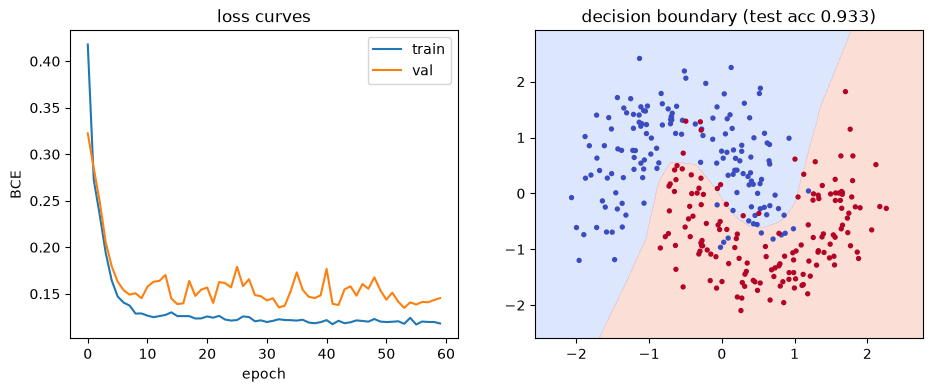

In [9]:
# 8. TEST + PLOTS. test_loss, test_acc = evaluate(model, test_dl) (touch test ONCE).
#    Plot (left) train/val loss curves; (right) decision boundary: predict sigmoid(logit) on a
#    300x300 mesh over the standardized input range, contourf at levels [0, .5, 1], scatter test points.
test_loss, test_acc = evaluate(model, test_dl)
print(f"test loss {test_loss:.3f} acc {test_acc:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["train_loss"], label="train")
ax[0].plot(history["val_loss"], label="val")
ax[0].set(xlabel="epoch", ylabel="BCE", title="loss curves")
ax[0].legend()
lo, hi = X_test.min(0).values - 0.5, X_test.max(0).values + 0.5
gx, gy = torch.meshgrid(torch.linspace(lo[0], hi[0], 300), torch.linspace(lo[1], hi[1], 300), indexing="xy")
grid = torch.stack([gx.ravel(), gy.ravel()], 1).to(dev)
model.eval()
with torch.no_grad():
    p = torch.sigmoid(model(grid)).reshape(gx.shape).cpu()
ax[1].contourf(gx, gy, p, levels=[0, 0.5, 1], alpha=0.3, cmap="coolwarm")
ax[1].scatter(X_test[:, 0], X_test[:, 1], c=y_test, s=8, cmap="coolwarm")
ax[1].set(title=f"decision boundary (test acc {test_acc:.3f})")
plt.show()

## Self-check
Expects: `mu`, `sd`, `X_train`, `model`, `init_loss`, `overfit_loss`, `history`, `test_acc`.

In [10]:
check("normalized with train stats", torch.allclose(X_train.mean(0), torch.zeros(2), atol=1e-4), "train mean should be ~0")
check("model has no Sigmoid layer", not any(isinstance(m, nn.Sigmoid) for m in model.modules()), "return logits; BCEWithLogits applies sigmoid")
out = model(X_train[:5].to(dev))
check("logits shape is (B,)", out.shape == (5,), f"got {tuple(out.shape)}; (B,1) vs (B,) silently broadcasts in BCE")
check("initial loss ~ ln 2", abs(init_loss - math.log(2)) < 0.15, f"got {init_loss:.3f}")
check("can overfit one batch", overfit_loss < 0.05, f"got {overfit_loss:.4f}")
check("history recorded", len(history["train_loss"]) > 0 and len(history["val_acc"]) == len(history["train_loss"]))
check("test accuracy > 0.90", test_acc > 0.90, f"got {test_acc:.3f}")

ok  normalized with train stats
ok  model has no Sigmoid layer
ok  logits shape is (B,)
ok  initial loss ~ ln 2
ok  can overfit one batch
ok  history recorded
ok  test accuracy > 0.90


## Say it out loud (P3)
1. Why does the model output logits and use `BCEWithLogitsLoss` instead of `Sigmoid` + `BCELoss`?
2. Why is the expected initial loss ln 2 here? What would you expect for C classes?
3. What does `model.eval()` change for *this* model? What does `torch.no_grad()` save?
4. Why compute val accuracy as total-correct / total-N rather than averaging per-batch accuracies?
5. Why standardize with train statistics only? What would leak otherwise?
6. What silently broadcasts if the model returns shape `(B, 1)` and targets are `(B,)`?

<details><summary>Model answers</summary>

1. `log(sigmoid(z))` underflows for very negative `z` (sigmoid → 0, log → -inf). The fused loss uses
   `max(z,0) - z·y + log(1 + exp(-|z|))`, which is stable for any `z`, and its gradient w.r.t. `z` is
   simply `sigmoid(z) - y`.
2. At init the logits are ≈ 0, so p ≈ 0.5 for every example and the loss is `-log 0.5 = ln 2 ≈ 0.693`.
   For C balanced classes with near-uniform softmax it is `ln C`. A much larger initial loss means the
   final layer is badly scaled (confidently wrong); fix the init, e.g. set the last bias to log class priors.
3. Nothing numerically for this model: it has no dropout or BatchNorm. It is still a habit worth keeping:
   the same loop would be wrong the moment someone adds those layers. `no_grad` stops autograd from
   recording the graph, so activations are not kept for backward. That saves memory and some time.
4. The last batch is usually smaller, so a mean of per-batch ratios weights its examples more heavily.
   For metrics that aren't averages (F1, AUC) the per-batch mean is simply wrong; aggregate first, then compute.
5. Val/test are a proxy for unseen data. Using their mean/std leaks information about the test
   distribution into training preprocessing, so the estimate becomes optimistically biased.
6. `BCEWithLogitsLoss` (B,1) vs (B,) raises a size-mismatch `ValueError`, but `MSELoss` broadcasts to (B, B) with only a
   `UserWarning`, and a hand-written `(pred - y)**2` broadcasts with no warning at all: always assert shapes.
</details>

In [11]:
s.finish(lookups=0, score=None, notes="")  # score: 1-5 self-rating; notes: what tripped you up

[P2.1] done in 0.1 min (within target 25 min)


0.11281099319458007